In [1]:
import numpy as np
import matplotlib.pyplot as plt; plt.rc('font', size=16)
import pandas as pd
from collections import Counter
import seaborn as sns

cmap = sns.color_palette("rocket_r", as_cmap=True)

In [2]:
taxa = ['B_cellulosilyticus_WH2', 
        'B_caccae', 
        'B_vulgatus', 
        'B_thetaiotaomicron', 
        'B_ovatus', 
        'R_obeum', 
        'B_uniformis', 
        'P_distasonis', 
        'C_scindens', 
        'C_aerofaciens', 
        'C_spiroforme', 
        # 'D_longicatena'
        ]

cols = ['#016bff',
        '#b91f1c',
        '#308937',
        '#ff8137',
        '#6f4fc7',
        '#d4b300',
        '#893a2b',
        '#ff6c79',
        '#16c4ff',
        '#766f41',
        '#00c800',
        '#af3261']

# pretty_names_dir = {'B_caccae': '$B. caccae$',
#                 'B_cellulosilyticus_WH2': '$B. cellulosilyticus$',
#                 'B_ovatus': '$B. ovatus$',
#                 'B_thetaiotaomicron': '$B. thetaiotaomicron$',
#                 'B_uniformis': '$B. uniformis$',
#                 'B_vulgatus': '$B. vulgatus$',
#                 'C_aerofaciens': '$C. aerofaciens$',
#                 'C_scindens': '$C. scindens$',
#                 'C_spiroforme': '$C. spiroforme$',
#                 # 'D_longicatena': '$D. longicatena$',
#                 'P_distasonis': '$P. distasonis$',
#                 'R_obeum': '$R. obeum$'}

pretty_names_dir = {'B_caccae': 'Bca',
                'B_cellulosilyticus_WH2': 'Bce',
                'B_ovatus': 'Bov',
                'B_thetaiotaomicron': 'Bth',
                'B_uniformis': 'Bun',
                'B_vulgatus': 'Bvu',
                'C_aerofaciens': 'Cae',
                'C_scindens': 'Csc',
                'C_spiroforme': 'Csp',
                # 'D_longicatena': 'Dlo',
                'P_distasonis': 'Pdi',
                'R_obeum': 'Rob'
                }

cols_species_map = dict(zip(taxa, cols))

In [3]:
def presence_absence(x):
    if pd.isna(x):
        return 0
    else:
        return 1
    
def drop_nan(x):
    if pd.isna(x):
        return False
    else:
        return True

def get_added_information(table):
    J = np.zeros([len(table.columns), len(table.columns)])
    probs = table.apply(sum, axis=1) / len(table.columns)
    for i in range(len(table.columns)):
        for j in range(len(table.columns)):
            if i == j:
                J[i,j] = 0
            else:
                K = table[(table.iloc[:,i] == 0) & (table.iloc[:,j] == 1)].copy().index
                J[i,j] = - np.sum(probs[K]*np.log2(probs[K]))
                if J[i,j] == -0:
                    J[i,j] = 0
    return pd.DataFrame(J, index=table.columns, columns=table.columns)         

def get_aminoacid_metabolism(COG):
    return 'E' in COG

def get_carbohydrate_metabolism(COG):
    return 'G' in COG

In [4]:
ECs = []
for taxon in taxa:
    eggNOG = pd.read_table(f'eggNOG/{taxon}_eggNOG.tsv', index_col=0, skiprows=4, skipfooter=3, engine='python')
    eggNOG['Species'] = taxon
    eggNOG = eggNOG[eggNOG['EC'] != '-'].copy()
    eggNOG.set_index('EC', inplace=True)
    eggNOG = eggNOG.loc[:,['Species']].copy()
    eggNOG.reset_index(inplace=True)
    eggNOG.set_index('Species', inplace=True)
    eggNOG = eggNOG['EC'].str.split(',', expand=True)
    eggNOG.reset_index(inplace=True)
    eggNOG = eggNOG.melt(id_vars='Species', value_name='EC')
    eggNOG.drop(columns='variable', inplace=True)
    eggNOG.dropna(inplace=True)
    eggNOG.drop_duplicates(subset=['EC'], inplace=True)
    eggNOG.set_index('EC', inplace=True)
    eggNOG.columns = [eggNOG['Species'][0]]
    ECs.append(eggNOG)
ECs = pd.concat(ECs, axis=1)
ECs = ECs.applymap(presence_absence)
ECs 

/tmp/ipykernel_20474/2071691111.py:17: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  eggNOG.columns = [eggNOG['Species'][0]]
/tmp/ipykernel_20474/2071691111.py:17: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  eggNOG.columns = [eggNOG['Species'][0]]
/tmp/ipykernel_20474/2071691111.py:17: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  eggNOG.columns = [eggNOG['Species'][0]]
/tmp/ipykernel_20474/2071691111.py:17: FutureWarning: Series.

,B_cellulosilyticus_WH2,B_caccae,B_vulgatus,B_thetaiotaomicron,B_ovatus,R_obeum,B_uniformis,P_distasonis,C_scindens,C_aerofaciens,C_spiroforme
EC,,,,,,,,,,,
4.3.2.1,1,1,1,1,1,1,1,1,1,1,0
2.4.2.10,1,1,1,1,1,1,1,1,1,1,1
2.1.1.297,1,1,1,1,1,1,1,1,1,1,1
1.1.1.193,1,1,1,1,1,1,1,1,0,0,0
2.5.1.31,1,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...
3.1.26.8,0,0,0,0,0,0,0,0,0,0,1
4.1.1.50,0,0,0,0,0,0,0,0,0,0,1
3.4.21.96,0,0,0,0,0,0,0,0,0,0,1


In [5]:
KOs = []
for taxon in taxa:
    eggNOG = pd.read_table(f'eggNOG/{taxon}_eggNOG.tsv', index_col=0, skiprows=4, skipfooter=3, engine='python')
    eggNOG['Species'] = taxon
    eggNOG = eggNOG[eggNOG['KEGG_ko'] != '-'].copy()
    eggNOG.set_index('KEGG_ko', inplace=True)
    eggNOG = eggNOG.loc[:,['Species']].copy()
    eggNOG.reset_index(inplace=True)
    eggNOG.set_index('Species', inplace=True)
    eggNOG = eggNOG['KEGG_ko'].str.split(',', expand=True)
    eggNOG.reset_index(inplace=True)
    eggNOG = eggNOG.melt(id_vars='Species', value_name='KEGG_ko')
    eggNOG.drop(columns='variable', inplace=True)
    eggNOG.dropna(inplace=True)
    eggNOG.drop_duplicates(subset=['KEGG_ko'], inplace=True)
    eggNOG['KEGG_ko'] = eggNOG['KEGG_ko'].apply(lambda x: x.replace('ko:', ''))
    eggNOG.set_index('KEGG_ko', inplace=True)
    eggNOG.columns = [eggNOG['Species'][0]]
    KOs.append(eggNOG)
KOs = pd.concat(KOs, axis=1)
KOs = KOs.applymap(presence_absence)
KOs 

/tmp/ipykernel_20474/3496788127.py:18: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  eggNOG.columns = [eggNOG['Species'][0]]
/tmp/ipykernel_20474/3496788127.py:18: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  eggNOG.columns = [eggNOG['Species'][0]]
/tmp/ipykernel_20474/3496788127.py:18: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  eggNOG.columns = [eggNOG['Species'][0]]
/tmp/ipykernel_20474/3496788127.py:18: FutureWarning: Series.

,B_cellulosilyticus_WH2,B_caccae,B_vulgatus,B_thetaiotaomicron,B_ovatus,R_obeum,B_uniformis,P_distasonis,C_scindens,C_aerofaciens,C_spiroforme
KEGG_ko,,,,,,,,,,,
K01755,1,1,1,1,1,1,1,1,1,1,0
K00762,1,1,1,1,1,1,1,1,1,1,1
K03565,1,1,1,1,1,1,1,1,1,1,0
K02493,1,1,1,1,1,1,1,1,1,1,1
K11752,1,1,1,1,1,1,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
K21687,0,0,0,0,0,0,0,0,0,0,1
K07093,0,0,0,0,0,0,0,0,0,0,1
K02041,0,0,0,0,0,0,0,0,0,0,1


# Carbohydrate metabolism

## Metabolic Distance and Metabolic Added Information

In [6]:
dbCAN_sub = []
for taxon in taxa:
    cazymes = pd.read_table(f'dbCAN3/{taxon}/overview.txt', sep='\t', index_col=1)
    cazymes['Species'] = taxon
    cazymes = cazymes[cazymes['#ofTools'] >= 2].loc[:, ['Species']].copy()
    cazymes.reset_index(inplace=True)
    cazymes.set_index('Species', inplace=True)
    cazymes = cazymes['EC#'].str.split('|', expand=True)
    cazymes.reset_index(inplace=True)
    cazymes = cazymes.melt(id_vars='Species', value_name='EC#')
    cazymes.drop(columns='variable', inplace=True)
    cazymes.dropna(inplace=True)
    cazymes = cazymes[cazymes['EC#'] != '-'].copy()
    cazymes.drop_duplicates(subset=['EC#'], inplace=True)
    cazymes.set_index('EC#', inplace=True)
    cazymes.columns = [cazymes['Species'][0]]
    dbCAN_sub.append(cazymes)
dbCAN_sub = pd.concat(dbCAN_sub, axis=1)
dbCAN_sub = dbCAN_sub.applymap(presence_absence)
dbCAN_sub

/tmp/ipykernel_20474/778627339.py:16: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cazymes.columns = [cazymes['Species'][0]]
/tmp/ipykernel_20474/778627339.py:16: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cazymes.columns = [cazymes['Species'][0]]
/tmp/ipykernel_20474/778627339.py:16: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cazymes.columns = [cazymes['Species'][0]]
/tmp/ipykernel_20474/778627339.py:16: FutureWarning: Serie

,B_cellulosilyticus_WH2,B_caccae,B_vulgatus,B_thetaiotaomicron,B_ovatus,R_obeum,B_uniformis,P_distasonis,C_scindens,C_aerofaciens,C_spiroforme
EC#,,,,,,,,,,,
3.2.1.55,1,1,1,1,1,1,1,1,0,0,0
3.2.1.37,1,1,1,1,1,1,1,1,0,1,1
3.2.1.-,1,1,1,1,1,1,1,1,1,1,1
3.2.1.92,1,0,0,0,0,0,1,0,0,0,0
3.2.1.21,1,1,1,1,1,1,1,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...
4.2.2.12,0,0,0,0,0,0,0,0,0,0,1
3.2.1.97,0,0,0,0,0,0,0,0,0,0,1
3.2.1.50,0,0,0,0,0,0,0,0,0,0,1


# Amino Acid Metabolism

 ## Metabolic distance and Metabolic Added Information

In [7]:
eggNOG = []
for taxon in taxa:
    aminoacid_metabolism = pd.read_table(f'eggNOG/{taxon}_eggNOG.tsv', index_col=0, skiprows=4, skipfooter=3, engine='python')
    aminoacid_metabolism['Species'] = taxon
    aminoacid_metabolism = aminoacid_metabolism[aminoacid_metabolism['COG_category'].apply(get_aminoacid_metabolism)].copy()
    aminoacid_metabolism = aminoacid_metabolism[aminoacid_metabolism['EC'] != '-'].copy()
    aminoacid_metabolism.set_index('EC', inplace=True)
    aminoacid_metabolism = aminoacid_metabolism.loc[:,['Species']].copy()
    aminoacid_metabolism.reset_index(inplace=True)
    aminoacid_metabolism.set_index('Species', inplace=True)
    aminoacid_metabolism = aminoacid_metabolism['EC'].str.split(',', expand=True)
    aminoacid_metabolism.reset_index(inplace=True)
    aminoacid_metabolism = aminoacid_metabolism.melt(id_vars='Species', value_name='EC')
    aminoacid_metabolism.drop(columns='variable', inplace=True)
    aminoacid_metabolism.dropna(inplace=True)
    aminoacid_metabolism.drop_duplicates(subset=['EC'], inplace=True)
    aminoacid_metabolism.set_index('EC', inplace=True)
    aminoacid_metabolism.columns = [aminoacid_metabolism['Species'][0]]
    eggNOG.append(aminoacid_metabolism)
eggNOG = pd.concat(eggNOG, axis=1)
eggNOG = eggNOG.applymap(presence_absence)
eggNOG 

/tmp/ipykernel_20474/1750677298.py:18: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  aminoacid_metabolism.columns = [aminoacid_metabolism['Species'][0]]
/tmp/ipykernel_20474/1750677298.py:18: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  aminoacid_metabolism.columns = [aminoacid_metabolism['Species'][0]]
/tmp/ipykernel_20474/1750677298.py:18: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  aminoacid_metabolism.columns = [aminoacid_met

,B_cellulosilyticus_WH2,B_caccae,B_vulgatus,B_thetaiotaomicron,B_ovatus,R_obeum,B_uniformis,P_distasonis,C_scindens,C_aerofaciens,C_spiroforme
EC,,,,,,,,,,,
4.3.2.1,1,1,1,1,1,1,1,1,1,1,0
2.7.2.11,1,1,1,1,1,0,1,1,0,1,1
1.2.1.41,1,1,1,1,1,1,1,1,1,1,1
2.1.3.11,1,1,1,1,1,0,1,1,0,0,0
1.2.1.11,1,1,1,1,1,0,1,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...
1.1.1.399,0,0,0,0,0,0,0,0,0,1,0
2.4.2.17,0,0,0,0,0,0,0,0,0,1,0
1.1.1.41,0,0,0,0,0,0,0,0,0,1,0


# Carbohydrate and Amino Acid Metabolism

 ## Metabolic Distance and Metabolic Added Information

In [8]:
dbCAN_sub_eggNOG = pd.concat([dbCAN_sub, eggNOG], axis=0)
dbCAN_sub_eggNOG

,B_cellulosilyticus_WH2,B_caccae,B_vulgatus,B_thetaiotaomicron,B_ovatus,R_obeum,B_uniformis,P_distasonis,C_scindens,C_aerofaciens,C_spiroforme
3.2.1.55,1,1,1,1,1,1,1,1,0,0,0
3.2.1.37,1,1,1,1,1,1,1,1,0,1,1
3.2.1.-,1,1,1,1,1,1,1,1,1,1,1
3.2.1.92,1,0,0,0,0,0,1,0,0,0,0
3.2.1.21,1,1,1,1,1,1,1,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...
1.1.1.399,0,0,0,0,0,0,0,0,0,1,0
2.4.2.17,0,0,0,0,0,0,0,0,0,1,0
1.1.1.41,0,0,0,0,0,0,0,0,0,1,0
2.1.3.6,0,0,0,0,0,0,0,0,0,1,0


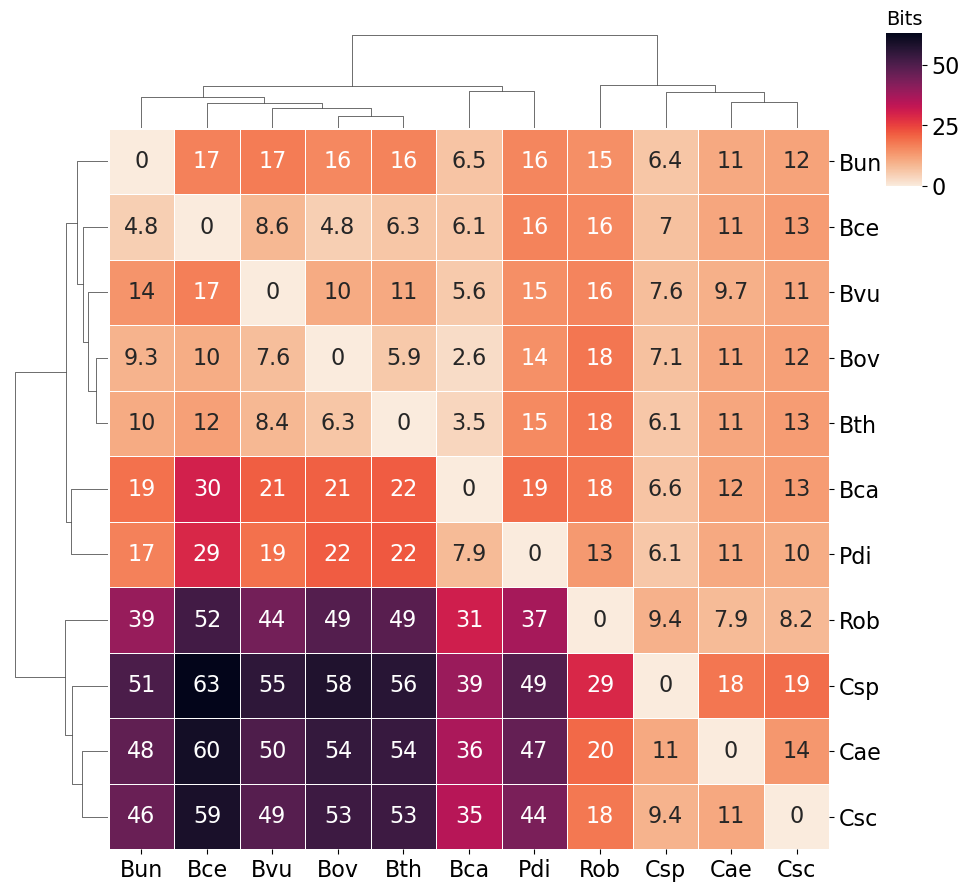

In [9]:
metaddinfo_carbo_amino = get_added_information(dbCAN_sub_eggNOG)
metaddinfo_carbo_amino = metaddinfo_carbo_amino.sort_index(axis=0).sort_index(axis=1)
metaddinfo_carbo_amino.to_csv('metabolic-metrics/metaddinfo_carbo_amino.tsv', sep='\t', index=True, header=True)
metaddinfo_carbo_amino_pretty = metaddinfo_carbo_amino.copy()
metaddinfo_carbo_amino_pretty.columns = metaddinfo_carbo_amino_pretty.columns.map(pretty_names_dir)
metaddinfo_carbo_amino_pretty.index = metaddinfo_carbo_amino_pretty.index.map(pretty_names_dir)
ax = sns.clustermap(metaddinfo_carbo_amino_pretty, 
    metric= 'chebyshev', 
    cmap=cmap, 
    dendrogram_ratio=(0.12, 0.12), 
    annot=True, 
    cbar_pos=(1, 0.8, 0.04, 0.17), 
    figsize=(9, 9), 
    linewidths=0.5
    )
cax = ax.ax_heatmap
cax.set_xticklabels(cax.get_xticklabels(), rotation=0, ha='center')
cax.set_yticklabels(cax.get_yticklabels(), rotation=0, ha='left')
# plt.title('Metabolic added\ninformation', fontsize=12)
plt.title('Bits', fontsize=14)
plt.savefig('metabolic-metrics/metaddinfo_carbo_amino.svg', bbox_inches='tight')
plt.show()

# Guided Whole Metabolism

## Metabolic Added Information

In [60]:
exp_mcnulty = pd.read_excel('expression_mcnulty.xlsx', index_col=0)
ecs_int = exp_mcnulty.loc[:,['EC']]
ecs_int = ecs_int['EC'].str.split('; ', expand=True)
ecs_int.reset_index(inplace=True)
ecs_int = ecs_int.melt(id_vars='Index', value_name='EC')
ecs_int = ecs_int.dropna()
ecs_int = ecs_int['EC'].values
print(ecs_int.shape)
ECs_int = ECs[ECs.index.isin(ecs_int)]
ECs_int

(157,)


,B_cellulosilyticus_WH2,B_caccae,B_vulgatus,B_thetaiotaomicron,B_ovatus,R_obeum,B_uniformis,P_distasonis,C_scindens,C_aerofaciens,C_spiroforme
EC,,,,,,,,,,,
2.7.2.1,1,1,1,1,1,1,1,1,1,1,1
5.3.1.4,1,1,1,1,1,1,1,0,0,0,0
2.6.1.37,1,1,1,1,1,0,1,1,0,0,0
3.2.1.4,1,0,0,1,1,0,1,0,0,0,0
2.7.1.4,1,1,1,1,1,1,1,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...
2.8.1.2,0,0,0,0,0,0,0,0,1,0,0
3.5.3.6,0,0,0,0,0,0,0,0,0,1,0
4.1.1.31,0,0,0,0,0,0,0,0,0,1,0


## Heatmaps

In [11]:
order_hm = ['Bce', 'Bov', 'Bth', 'Bvu', 'Bun', 'Bca', 'Pdi', 'Csc', 'Rob', 'Csp', 'Cae']

In [12]:
metabolic_added_info_sum = {}
metabolic_added_info_mean = {}

(84,)


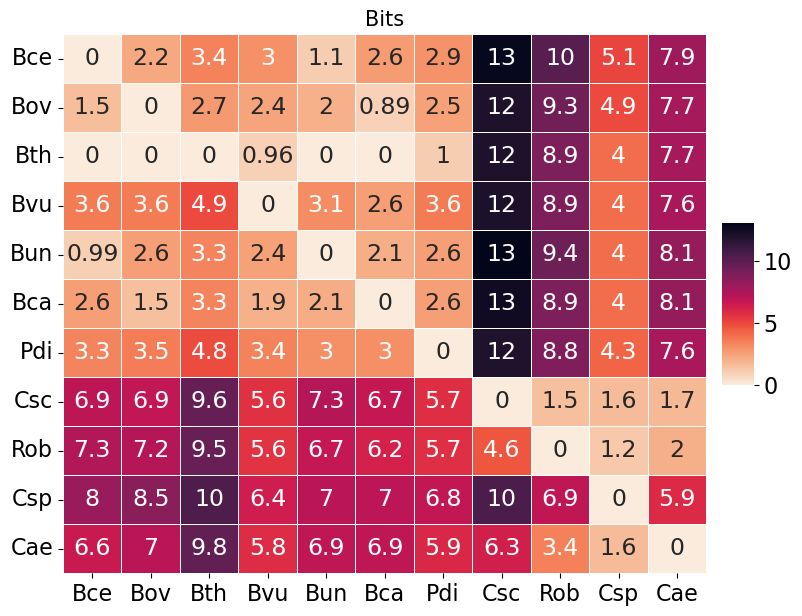

In [13]:
exp_mcnulty = pd.read_excel('expression_mcnulty.xlsx', index_col=0)
ecs_int_hf = exp_mcnulty.loc[1:81,['EC']]
ecs_int_hf = ecs_int_hf['EC'].str.split('; ', expand=True)
ecs_int_hf.reset_index(inplace=True)
ecs_int_hf = ecs_int_hf.melt(id_vars='Index', value_name='EC')
ecs_int_hf = ecs_int_hf.dropna()
ecs_int_hf = ecs_int_hf['EC'].values
print(ecs_int_hf.shape)
ECs_int_hf = ECs[ECs.index.isin(ecs_int_hf)]

metaddinfo_ECs_int_hf = get_added_information(ECs_int_hf)
metaddinfo_ECs_int_hf = metaddinfo_ECs_int_hf.sort_index(axis=0).sort_index(axis=1)
metaddinfo_ECs_int_hf.to_csv('metabolic-metrics/metaddinfo_ECs_int_hf_complete.tsv', sep='\t', index=True, header=True)
metaddinfo_ECs_int_hf_pretty = metaddinfo_ECs_int_hf.copy()
metaddinfo_ECs_int_hf_pretty.columns = metaddinfo_ECs_int_hf_pretty.columns.map(pretty_names_dir)
metaddinfo_ECs_int_hf_pretty.index = metaddinfo_ECs_int_hf_pretty.index.map(pretty_names_dir)
metaddinfo_ECs_int_hf_pretty = metaddinfo_ECs_int_hf_pretty.loc[order_hm, order_hm]
plt.figure(figsize=(10, 7))
ax = sns.heatmap(metaddinfo_ECs_int_hf_pretty, 
    cmap=cmap, 
    annot=True, 
    annot_kws={'size': 17},
    linewidths=0.5,
    cbar_kws={'shrink': 0.3, 'aspect': 5, 'orientation':'vertical', 'pad': 0.02},
    xticklabels=True,
    )
ax.set_yticklabels(ax.get_xticklabels(), rotation=0)
plt.title('Bits', fontsize=15)
plt.savefig('metabolic-metrics/metaddinfo_ECs_int_hf_complete.svg', bbox_inches='tight')
plt.show()

metabolic_added_info_sum['ECs_int_hf_complete_Community'] = metaddinfo_ECs_int_hf_pretty.values.sum()
metabolic_added_info_sum['ECs_int_hf_complete_Bacteroidetes'] = metaddinfo_ECs_int_hf_pretty.iloc[7:,:7].values.sum()
metabolic_added_info_sum['ECs_int_hf_complete_Others'] = metaddinfo_ECs_int_hf_pretty.iloc[:7,7:].values.sum()

metabolic_added_info_mean['ECs_int_hf_complete_Community'] = metaddinfo_ECs_int_hf_pretty.values.mean()
metabolic_added_info_mean['ECs_int_hf_complete_Bacteroidetes'] = metaddinfo_ECs_int_hf_pretty.iloc[7:,:7].values.mean()
metabolic_added_info_mean['ECs_int_hf_complete_Others'] = metaddinfo_ECs_int_hf_pretty.iloc[:7,7:].values.mean()

(79,)


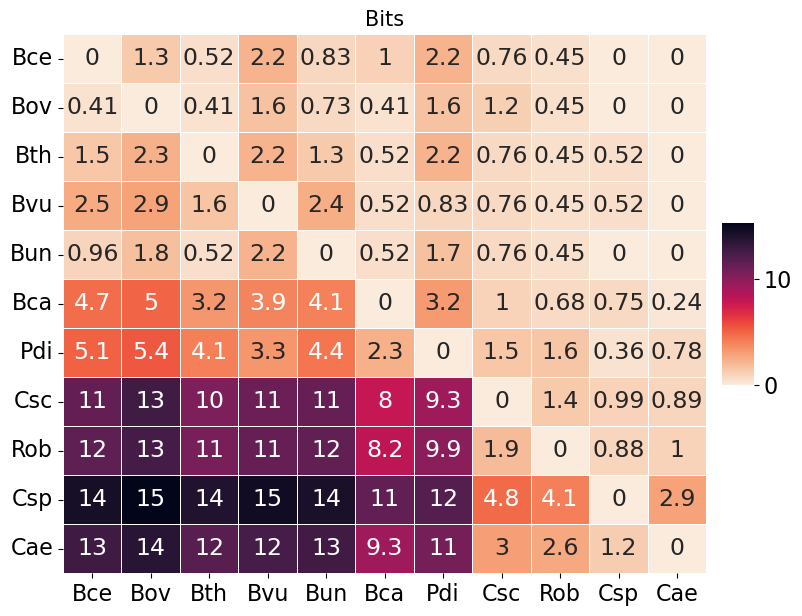

In [14]:
exp_mcnulty = pd.read_excel('expression_mcnulty.xlsx', index_col=0)
ecs_int_lf = exp_mcnulty.loc[82:157,['EC']]
ecs_int_lf = ecs_int_lf['EC'].str.split('; ', expand=True)
ecs_int_lf.reset_index(inplace=True)
ecs_int_lf = ecs_int_lf.melt(id_vars='Index', value_name='EC')
ecs_int_lf = ecs_int_lf.dropna()
ecs_int_lf = ecs_int_lf['EC'].values
print(ecs_int_lf.shape)
ECs_int_lf = ECs[ECs.index.isin(ecs_int_lf)]

metaddinfo_ECs_int_lf = get_added_information(ECs_int_lf)
metaddinfo_ECs_int_lf = metaddinfo_ECs_int_lf.sort_index(axis=0).sort_index(axis=1)
metaddinfo_ECs_int_lf.to_csv('metabolic-metrics/metaddinfo_ECs_int_lf_complete.tsv', sep='\t', index=True, header=True)
metaddinfo_ECs_int_lf_pretty = metaddinfo_ECs_int_lf.copy()
metaddinfo_ECs_int_lf_pretty.columns = metaddinfo_ECs_int_lf_pretty.columns.map(pretty_names_dir)
metaddinfo_ECs_int_lf_pretty.index = metaddinfo_ECs_int_lf_pretty.index.map(pretty_names_dir)
metaddinfo_ECs_int_lf_pretty = metaddinfo_ECs_int_lf_pretty.loc[order_hm, order_hm]
plt.figure(figsize=(10, 7))
ax = sns.heatmap(metaddinfo_ECs_int_lf_pretty, 
    cmap=cmap, 
    annot=True, 
    annot_kws={'size': 17},
    linewidths=0.5,
    cbar_kws={'shrink': 0.3, 'aspect': 5, 'orientation':'vertical', 'pad': 0.02},
    xticklabels=True,
    )
ax.set_yticklabels(ax.get_xticklabels(), rotation=0)
plt.title('Bits', fontsize=15)
plt.savefig('metabolic-metrics/metaddinfo_ECs_int_lf_complete.svg', bbox_inches='tight')
plt.show()

metabolic_added_info_sum['ECs_int_lf_complete_Community'] = metaddinfo_ECs_int_lf_pretty.values.sum()
metabolic_added_info_sum['ECs_int_lf_complete_Bacteroidetes'] = metaddinfo_ECs_int_lf_pretty.iloc[7:,:7].values.sum()
metabolic_added_info_sum['ECs_int_lf_complete_Others'] = metaddinfo_ECs_int_lf_pretty.iloc[:7,7:].values.sum()

metabolic_added_info_mean['ECs_int_lf_complete_Community'] = metaddinfo_ECs_int_lf_pretty.values.mean()
metabolic_added_info_mean['ECs_int_lf_complete_Bacteroidetes'] = metaddinfo_ECs_int_lf_pretty.iloc[7:,:7].values.mean()
metabolic_added_info_mean['ECs_int_lf_complete_Others'] = metaddinfo_ECs_int_lf_pretty.iloc[:7,7:].values.mean()

(24,)


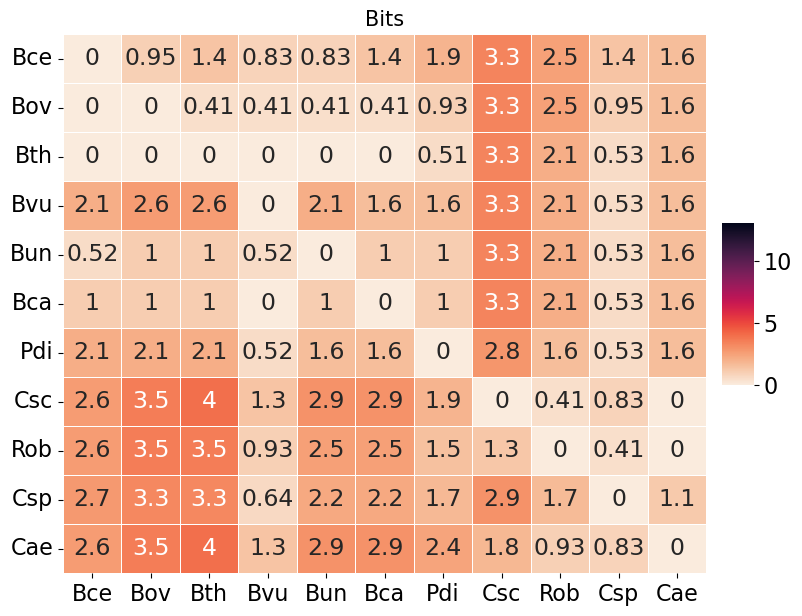

In [15]:
exp_mcnulty = pd.read_excel('expression_mcnulty.xlsx', index_col=0)
ecs_int_hf_carbo = exp_mcnulty.loc[1:81,['EC','Carbohydrate_metabolism']].dropna()
ecs_int_hf_carbo.drop(columns=['Carbohydrate_metabolism'], inplace=True)
ecs_int_hf_carbo = ecs_int_hf_carbo['EC'].str.split('; ', expand=True)
ecs_int_hf_carbo.reset_index(inplace=True)
ecs_int_hf_carbo = ecs_int_hf_carbo.melt(id_vars='Index', value_name='EC')
ecs_int_hf_carbo = ecs_int_hf_carbo.dropna()
ecs_int_hf_carbo = ecs_int_hf_carbo['EC'].values
print(ecs_int_hf_carbo.shape)
ECs_int_lf = ECs[ECs.index.isin(ecs_int_hf_carbo)]

metaddinfo_ECs_int_hf_carbo = get_added_information(ECs_int_lf)
metaddinfo_ECs_int_hf_carbo = metaddinfo_ECs_int_hf_carbo.sort_index(axis=0).sort_index(axis=1)
metaddinfo_ECs_int_hf_carbo.to_csv('metabolic-metrics/metaddinfo_ECs_int_hf_carbo.tsv', sep='\t', index=True, header=True)
metaddinfo_ECs_int_hf_carbo_pretty = metaddinfo_ECs_int_hf_carbo.copy()
metaddinfo_ECs_int_hf_carbo_pretty.columns = metaddinfo_ECs_int_hf_carbo_pretty.columns.map(pretty_names_dir)
metaddinfo_ECs_int_hf_carbo_pretty.index = metaddinfo_ECs_int_hf_carbo_pretty.index.map(pretty_names_dir)
metaddinfo_ECs_int_hf_carbo_pretty = metaddinfo_ECs_int_hf_carbo_pretty.loc[order_hm, order_hm]
plt.figure(figsize=(10, 7))
ax = sns.heatmap(metaddinfo_ECs_int_hf_carbo_pretty, 
    cmap=cmap, 
    annot=True, 
    annot_kws={'size': 17},
    linewidths=0.5,
    vmin=0,
    vmax=metaddinfo_ECs_int_hf_pretty.max().max(),
    cbar_kws={'shrink': 0.3, 'aspect': 5, 'orientation':'vertical', 'pad': 0.02},
    xticklabels=True,
    )
ax.set_yticklabels(ax.get_xticklabels(), rotation=0)
plt.title('Bits', fontsize=15)
plt.savefig('metabolic-metrics/metaddinfo_ECs_int_hf_carbo.svg', bbox_inches='tight')
plt.show()

metabolic_added_info_sum['ECs_int_hf_carbo_Community'] = metaddinfo_ECs_int_hf_carbo_pretty.values.sum()
metabolic_added_info_sum['ECs_int_hf_carbo_Bacteroidetes'] = metaddinfo_ECs_int_hf_carbo_pretty.iloc[7:,:7].values.sum()
metabolic_added_info_sum['ECs_int_hf_carbo_Others'] = metaddinfo_ECs_int_hf_carbo_pretty.iloc[:7,7:].values.sum()

metabolic_added_info_mean['ECs_int_hf_carbo_Community'] = metaddinfo_ECs_int_hf_carbo_pretty.values.mean()
metabolic_added_info_mean['ECs_int_hf_carbo_Bacteroidetes'] = metaddinfo_ECs_int_hf_carbo_pretty.iloc[7:,:7].values.mean()
metabolic_added_info_mean['ECs_int_hf_carbo_Others'] = metaddinfo_ECs_int_hf_carbo_pretty.iloc[:7,7:].values.mean()

(28,)


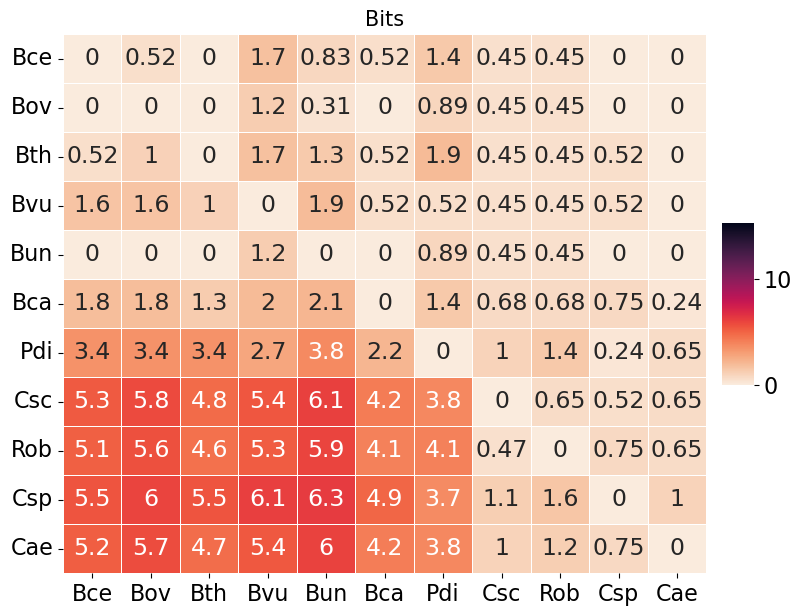

In [16]:
exp_mcnulty = pd.read_excel('expression_mcnulty.xlsx', index_col=0)
ecs_int_lf_carbo = exp_mcnulty.loc[82:158,['EC','Carbohydrate_metabolism']].dropna()
ecs_int_lf_carbo.drop(columns=['Carbohydrate_metabolism'], inplace=True)
ecs_int_lf_carbo = ecs_int_lf_carbo['EC'].str.split('; ', expand=True)
ecs_int_lf_carbo.reset_index(inplace=True)
ecs_int_lf_carbo = ecs_int_lf_carbo.melt(id_vars='Index', value_name='EC')
ecs_int_lf_carbo = ecs_int_lf_carbo.dropna()
ecs_int_lf_carbo = ecs_int_lf_carbo['EC'].values
print(ecs_int_lf_carbo.shape)
ECs_int_lf = ECs[ECs.index.isin(ecs_int_lf_carbo)]

metaddinfo_ECs_int_lf_carbo = get_added_information(ECs_int_lf)
metaddinfo_ECs_int_lf_carbo = metaddinfo_ECs_int_lf_carbo.sort_index(axis=0).sort_index(axis=1)
metaddinfo_ECs_int_lf_carbo.to_csv('metabolic-metrics/metaddinfo_ECs_int_lf_carbo.tsv', sep='\t', index=True, header=True)
metaddinfo_ECs_int_lf_carbo_pretty = metaddinfo_ECs_int_lf_carbo.copy()
metaddinfo_ECs_int_lf_carbo_pretty.columns = metaddinfo_ECs_int_lf_carbo_pretty.columns.map(pretty_names_dir)
metaddinfo_ECs_int_lf_carbo_pretty.index = metaddinfo_ECs_int_lf_carbo_pretty.index.map(pretty_names_dir)
metaddinfo_ECs_int_lf_carbo_pretty = metaddinfo_ECs_int_lf_carbo_pretty.loc[order_hm, order_hm]
plt.figure(figsize=(10, 7))
ax = sns.heatmap(metaddinfo_ECs_int_lf_carbo_pretty, 
    cmap=cmap, 
    annot=True, 
    annot_kws={'size': 17},
    linewidths=0.5,
    vmin=0,
    vmax=metaddinfo_ECs_int_lf_pretty.max().max(),
    cbar_kws={'shrink': 0.3, 'aspect': 5, 'orientation':'vertical', 'pad': 0.02},
    xticklabels=True,
    )
ax.set_yticklabels(ax.get_xticklabels(), rotation=0)
plt.title('Bits', fontsize=15)
plt.savefig('metabolic-metrics/metaddinfo_ECs_int_lf_carbo.svg', bbox_inches='tight')
plt.show()

metabolic_added_info_sum['ECs_int_lf_carbo_Community'] = metaddinfo_ECs_int_lf_carbo_pretty.values.sum()
metabolic_added_info_sum['ECs_int_lf_carbo_Bacteroidetes'] = metaddinfo_ECs_int_lf_carbo_pretty.iloc[7:,:7].values.sum()
metabolic_added_info_sum['ECs_int_lf_carbo_Others'] = metaddinfo_ECs_int_lf_carbo_pretty.iloc[:7,7:].values.sum()

metabolic_added_info_mean['ECs_int_lf_carbo_Community'] = metaddinfo_ECs_int_lf_carbo_pretty.values.mean()
metabolic_added_info_mean['ECs_int_lf_carbo_Bacteroidetes'] = metaddinfo_ECs_int_lf_carbo_pretty.iloc[7:,:7].values.mean()
metabolic_added_info_mean['ECs_int_lf_carbo_Others'] = metaddinfo_ECs_int_lf_carbo_pretty.iloc[:7,7:].values.mean()

(19,)


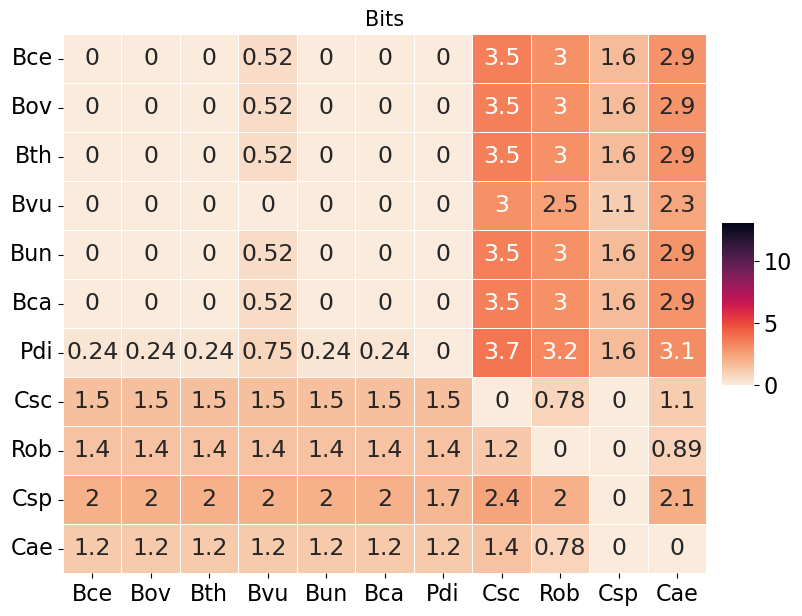

In [17]:
exp_mcnulty = pd.read_excel('expression_mcnulty.xlsx', index_col=0)
ecs_int_hf_amino = exp_mcnulty.loc[1:81,['EC','Aminocid_metabolism']].dropna()
ecs_int_hf_amino.drop(columns=['Aminocid_metabolism'], inplace=True)
ecs_int_hf_amino = ecs_int_hf_amino['EC'].str.split('; ', expand=True)
ecs_int_hf_amino.reset_index(inplace=True)
ecs_int_hf_amino = ecs_int_hf_amino.melt(id_vars='Index', value_name='EC')
ecs_int_hf_amino = ecs_int_hf_amino.dropna()
ecs_int_hf_amino = ecs_int_hf_amino['EC'].values
print(ecs_int_hf_amino.shape)
ECs_int_lf = ECs[ECs.index.isin(ecs_int_hf_amino)]

metaddinfo_ECs_int_hf_amino = get_added_information(ECs_int_lf)
metaddinfo_ECs_int_hf_amino = metaddinfo_ECs_int_hf_amino.sort_index(axis=0).sort_index(axis=1)
metaddinfo_ECs_int_hf_amino.to_csv('metabolic-metrics/metaddinfo_ECs_int_hf_amino.tsv', sep='\t', index=True, header=True)
metaddinfo_ECs_int_hf_amino_pretty = metaddinfo_ECs_int_hf_amino.copy()
metaddinfo_ECs_int_hf_amino_pretty.columns = metaddinfo_ECs_int_hf_amino_pretty.columns.map(pretty_names_dir)
metaddinfo_ECs_int_hf_amino_pretty.index = metaddinfo_ECs_int_hf_amino_pretty.index.map(pretty_names_dir)
metaddinfo_ECs_int_hf_amino_pretty = metaddinfo_ECs_int_hf_amino_pretty.loc[order_hm, order_hm]
plt.figure(figsize=(10, 7))
ax = sns.heatmap(metaddinfo_ECs_int_hf_amino_pretty, 
    cmap=cmap, 
    annot=True, 
    annot_kws={'size': 17},
    linewidths=0.5,
    vmin=0,
    vmax=metaddinfo_ECs_int_hf_pretty.max().max(),
    cbar_kws={'shrink': 0.3, 'aspect': 5, 'orientation':'vertical', 'pad': 0.02},
    xticklabels=True,
    )
ax.set_yticklabels(ax.get_xticklabels(), rotation=0)
plt.title('Bits', fontsize=15)
plt.savefig('metabolic-metrics/metaddinfo_ECs_int_hf_amino.svg', bbox_inches='tight')
plt.show()

metabolic_added_info_sum['ECs_int_hf_amino_Community'] = metaddinfo_ECs_int_hf_amino_pretty.values.sum()
metabolic_added_info_sum['ECs_int_hf_amino_Bacteroidetes'] = metaddinfo_ECs_int_hf_amino_pretty.iloc[7:,:7].values.sum()
metabolic_added_info_sum['ECs_int_hf_amino_Others'] = metaddinfo_ECs_int_hf_amino_pretty.iloc[:7,7:].values.sum()

metabolic_added_info_mean['ECs_int_hf_amino_Community'] = metaddinfo_ECs_int_hf_amino_pretty.values.mean()
metabolic_added_info_mean['ECs_int_hf_amino_Bacteroidetes'] = metaddinfo_ECs_int_hf_amino_pretty.iloc[7:,:7].values.mean()
metabolic_added_info_mean['ECs_int_hf_amino_Others'] = metaddinfo_ECs_int_hf_amino_pretty.iloc[:7,7:].values.mean()

(25,)


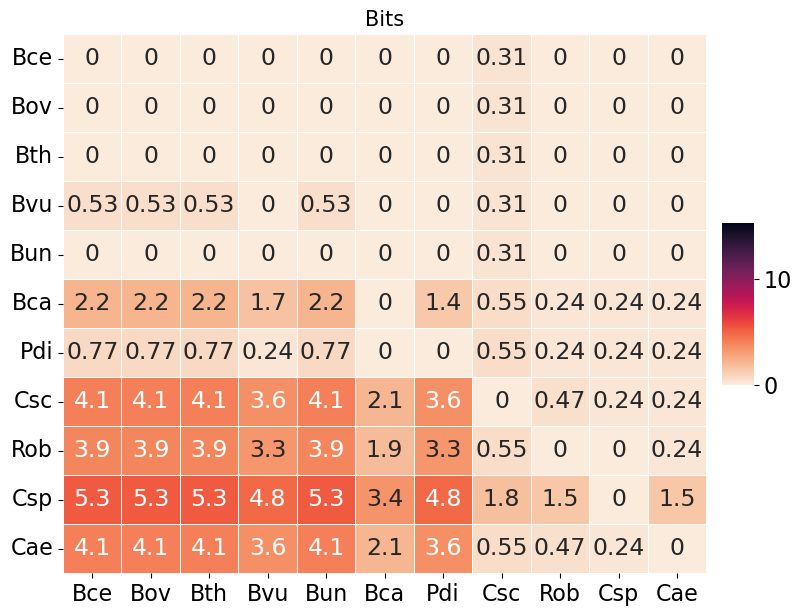

In [18]:
exp_mcnulty = pd.read_excel('expression_mcnulty.xlsx', index_col=0)
ecs_int_df_amino = exp_mcnulty.loc[82:158,['EC','Aminocid_metabolism']].dropna()
ecs_int_df_amino.drop(columns=['Aminocid_metabolism'], inplace=True)
ecs_int_df_amino = ecs_int_df_amino['EC'].str.split('; ', expand=True)
ecs_int_df_amino.reset_index(inplace=True)
ecs_int_df_amino = ecs_int_df_amino.melt(id_vars='Index', value_name='EC')
ecs_int_df_amino = ecs_int_df_amino.dropna()
ecs_int_df_amino = ecs_int_df_amino['EC'].values
print(ecs_int_df_amino.shape)
ECs_int_lf = ECs[ECs.index.isin(ecs_int_df_amino)]

metaddinfo_ECs_int_lf_amino = get_added_information(ECs_int_lf)
metaddinfo_ECs_int_lf_amino = metaddinfo_ECs_int_lf_amino.sort_index(axis=0).sort_index(axis=1)
metaddinfo_ECs_int_lf_amino.to_csv('metabolic-metrics/metaddinfo_ECs_int_lf_amino.tsv', sep='\t', index=True, header=True)
metaddinfo_ECs_int_lf_amino_pretty = metaddinfo_ECs_int_lf_amino.copy()
metaddinfo_ECs_int_lf_amino_pretty.columns = metaddinfo_ECs_int_lf_amino_pretty.columns.map(pretty_names_dir)
metaddinfo_ECs_int_lf_amino_pretty.index = metaddinfo_ECs_int_lf_amino_pretty.index.map(pretty_names_dir)
metaddinfo_ECs_int_lf_amino_pretty = metaddinfo_ECs_int_lf_amino_pretty.loc[order_hm, order_hm]
plt.figure(figsize=(10, 7))
ax = sns.heatmap(metaddinfo_ECs_int_lf_amino_pretty, 
    cmap=cmap, 
    annot=True, 
    annot_kws={'size': 17},
    linewidths=0.5,
    vmin=0,
    vmax=metaddinfo_ECs_int_lf_pretty.max().max(),
    cbar_kws={'shrink': 0.3, 'aspect': 5, 'orientation':'vertical', 'pad': 0.02},
    xticklabels=True,
    )
ax.set_yticklabels(ax.get_xticklabels(), rotation=0)
plt.title('Bits', fontsize=15)
plt.savefig('metabolic-metrics/metaddinfo_ECs_int_lf_amino.svg', bbox_inches='tight')
plt.show()

metabolic_added_info_sum['ECs_int_lf_amino_Community'] = metaddinfo_ECs_int_lf_amino_pretty.values.sum()
metabolic_added_info_sum['ECs_int_lf_amino_Bacteroidetes'] = metaddinfo_ECs_int_lf_amino_pretty.iloc[7:,:7].values.sum()
metabolic_added_info_sum['ECs_int_lf_amino_Others'] = metaddinfo_ECs_int_lf_amino_pretty.iloc[:7,7:].values.sum()

metabolic_added_info_mean['ECs_int_lf_amino_Community'] = metaddinfo_ECs_int_lf_amino_pretty.values.mean()
metabolic_added_info_mean['ECs_int_lf_amino_Bacteroidetes'] = metaddinfo_ECs_int_lf_amino_pretty.iloc[7:,:7].values.mean()
metabolic_added_info_mean['ECs_int_lf_amino_Others'] = metaddinfo_ECs_int_lf_amino_pretty.iloc[:7,7:].values.mean()

In [19]:
metabolic_added_info_sum_df = pd.DataFrame.from_dict(metabolic_added_info_sum, orient='index', columns=['Total bits'])
metabolic_added_info_sum_df.index.name = 'metabolic_category'
metabolic_added_info_sum_df.reset_index(inplace=True)
metabolic_added_info_sum_df[['EC', 'int', 'Treatment', 'Metabolic category', 'Phylum']] = metabolic_added_info_sum_df['metabolic_category'].str.split('_', expand=True)
metabolic_added_info_sum_df.drop(columns=['metabolic_category', 'EC', 'int'], inplace=True)
metabolic_added_info_sum_df['Metabolic category'] = metabolic_added_info_sum_df['Metabolic category'].map({'complete':'Complete metabolism',
                                                                                'carbo':'Carbohydrate metabolism',
                                                                                'amino':'Amino acid metabolism'})
metabolic_added_info_sum_df['Treatment'] = metabolic_added_info_sum_df['Treatment'].str.upper()
metabolic_added_info_sum_df.set_index(['Metabolic category', 'Treatment', 'Phylum'], inplace=True)
metabolic_added_info_sum_df

Total bits
Metabolic category      Treatment Phylum                   
Complete metabolism     HF        Community      582.861562
                                  Bacteroidetes  200.160275
                                  Others         235.777183
                        LF        Community      460.451687
                                  Bacteroidetes  329.715203
                                  Others          14.321072
Carbohydrate metabolism HF        Community      180.499832
                                  Bacteroidetes   71.862523
                                  Others          53.346101
                        LF        Community      217.688532
                                  Bacteroidetes  143.083759
                                  Others          11.204645
Amino acid metabolism   HF        Community      133.981116
                                  Bacteroidetes   42.008571
                                  Others          74.901236
                        LF        Community      138.726845
                                  Bacteroidetes  109.574156
                                  Others           4.096409

In [20]:
metabolic_added_info_mean_df = pd.DataFrame.from_dict(metabolic_added_info_mean, orient='index', columns=['Total bits'])
metabolic_added_info_mean_df.index.name = 'metabolic_category'
metabolic_added_info_mean_df.reset_index(inplace=True)
metabolic_added_info_mean_df[['EC', 'int', 'Treatment', 'Metabolic category', 'Phylum']] = metabolic_added_info_mean_df['metabolic_category'].str.split('_', expand=True)
metabolic_added_info_mean_df.drop(columns=['metabolic_category', 'EC', 'int'], inplace=True)
metabolic_added_info_mean_df['Metabolic category'] = metabolic_added_info_mean_df['Metabolic category'].map({'complete':'Complete metabolism',
                                                                                'carbo':'Carbohydrate metabolism',
                                                                                'amino':'Amino acid metabolism'})
metabolic_added_info_mean_df['Treatment'] = metabolic_added_info_mean_df['Treatment'].str.upper()
metabolic_added_info_mean_df.set_index(['Metabolic category', 'Treatment', 'Phylum'], inplace=True)
metabolic_added_info_mean_df

Total bits
Metabolic category      Treatment Phylum                   
Complete metabolism     HF        Community        4.817038
                                  Bacteroidetes    7.148581
                                  Others           8.420614
                        LF        Community        3.805386
                                  Bacteroidetes   11.775543
                                  Others           0.511467
Carbohydrate metabolism HF        Community        1.491734
                                  Bacteroidetes    2.566519
                                  Others           1.905218
                        LF        Community        1.799079
                                  Bacteroidetes    5.110134
                                  Others           0.400166
Amino acid metabolism   HF        Community        1.107282
                                  Bacteroidetes    1.500306
                                  Others           2.675044
                        LF        Community        1.146503
                                  Bacteroidetes    3.913363
                                  Others           0.146300

In [21]:
with pd.ExcelWriter('metabolic-metrics/metabolic_added_info_total_df.xlsx') as writer:
    metabolic_added_info_sum_df.to_excel(writer, sheet_name= 'sum', index=True, header=True)
    metabolic_added_info_mean_df.to_excel(writer, sheet_name= 'mean', index=True, header=True)

---

In [61]:
def get_added_information_contribution(table):
    exp_mcnulty = pd.read_excel('expression_mcnulty.xlsx', index_col=0)
    exp_mcnulty = exp_mcnulty.loc[:, ['EC', 'Description', 'Response type', 'Carbohydrate_metabolism', 'Aminocid_metabolism']].copy()
    probs = table.apply(sum, axis=1) / len(table.columns)
    dfs = []
    for i in range(len(table.columns)):
        for j in range(len(table.columns)):
            if i == j:
                continue
            else:
                K = table[(table.iloc[:,i] == 0) & (table.iloc[:,j] == 1)].copy().index
                K_df = - probs[K].copy() * np.log2(probs[K].copy())
                K_df = pd.DataFrame(K_df)
                K_df.columns = ['added_info']
                K_df['A'] = table.columns[i]
                K_df['B'] = table.columns[j]
                K_df.reset_index(inplace=True)
                K_df = K_df.loc[:,['A', 'B', 'EC', 'added_info']]
                dfs.append(K_df)
    df = pd.concat(dfs, ignore_index=True)
    df = df.merge(exp_mcnulty, on='EC', how='left')
    return df

In [62]:
exp_mcnulty = pd.read_excel('expression_mcnulty.xlsx', index_col=0)
ecs_int = exp_mcnulty.loc[:,['EC']]
# ecs_int = ecs_int['EC'].str.split('; ', expand=True)
ecs_int.reset_index(inplace=True)
# ecs_int = ecs_int.melt(id_vars='Index', value_name='EC')
ecs_int = ecs_int.dropna()
ecs_int = ecs_int['EC'].values
print(ecs_int.shape)
ECs_int = ECs[ECs.index.isin(ecs_int)]
ECs_int

(157,)


,B_cellulosilyticus_WH2,B_caccae,B_vulgatus,B_thetaiotaomicron,B_ovatus,R_obeum,B_uniformis,P_distasonis,C_scindens,C_aerofaciens,C_spiroforme
EC,,,,,,,,,,,
2.7.2.1,1,1,1,1,1,1,1,1,1,1,1
5.3.1.4,1,1,1,1,1,1,1,0,0,0,0
2.6.1.37,1,1,1,1,1,0,1,1,0,0,0
3.2.1.4,1,0,0,1,1,0,1,0,0,0,0
2.7.1.4,1,1,1,1,1,1,1,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...
2.8.1.2,0,0,0,0,0,0,0,0,1,0,0
3.5.3.6,0,0,0,0,0,0,0,0,0,1,0
4.1.1.31,0,0,0,0,0,0,0,0,0,1,0


In [81]:
added_info_contr = get_added_information_contribution(ECs_int)
added_info_contr.to_csv('metabolic-metrics/added_info_contr.tsv', sep='\t', index=True, header=True)
added_info_contr['diet'] = added_info_contr['Response type'].apply(lambda x: 'HF/HS' if x in ['Rapid, up on HF/HS', 'Gradual, up on HF/HS', 'Delayed, up on HF/HS'] else 'LF/HPP')
added_info_contr['Carbohydrate_metabolism'] = added_info_contr['Carbohydrate_metabolism'].map({'Y': 'Carbohydrate metabolism'})
added_info_contr['Aminocid_metabolism'] = added_info_contr['Aminocid_metabolism'].map({'Y': 'Amino acid metabolism'})
added_info_contr['Metabolic category'] = (added_info_contr['Carbohydrate_metabolism'].fillna('') + ' ' + added_info_contr['Aminocid_metabolism'].fillna('') + ' ').str.strip()
added_info_contr.drop(columns=['Response type', 'Carbohydrate_metabolism', 'Aminocid_metabolism'], inplace=True)
added_info_contr

,A,B,EC,added_info,Description,diet,Metabolic category
0,B_cellulosilyticus_WH2,B_caccae,3.2.1.18,0.414958,Exo-alpha-sialidase,HF/HS,Carbohydrate metabolism
1,B_cellulosilyticus_WH2,B_caccae,4.1.3.36,0.517047,"1,4-dihydroxy-2-naphthoyl-CoA synthase",HF/HS,
2,B_cellulosilyticus_WH2,B_caccae,2.4.1.15,0.517047,"Alpha,alpha-trehalose-phosphate synthase (UDP-...",LF/HPP,Carbohydrate metabolism
3,B_cellulosilyticus_WH2,B_caccae,1.2.5.1,0.530702,Pyruvate dehydrogenase (quinone),HF/HS,Carbohydrate metabolism
4,B_cellulosilyticus_WH2,B_caccae,1.16.3.1,0.517047,Ferroxidase,LF/HPP,
...,...,...,...,...,...,...,...
2351,C_spiroforme,C_aerofaciens,1.97.1.9,0.511219,Selenate reductase,HF/HS,
2352,C_spiroforme,C_aerofaciens,2.7.7.27,0.511219,Glucose-1-phosphate adenylyltransferase,HF/HS,Carbohydrate metabolism
2353,C_spiroforme,C_aerofaciens,3.5.3.6,0.314494,Arginine deiminase,HF/HS,Amino acid metabolism
2354,C_spiroforme,C_aerofaciens,4.1.1.31,0.314494,Phosphoenolpyruvate carboxylase,HF/HS,


In [82]:
added_info_contr_lf = added_info_contr[added_info_contr['diet'] == 'LF/HPP'].copy()
added_info_contr_hf = added_info_contr[added_info_contr['diet'] == 'HF/HS'].copy()

In [83]:
with pd.ExcelWriter('metabolic-metrics/metabolic_added_info_contributions.xlsx') as writer:
    added_info_contr.to_excel(writer, sheet_name= 'Both', index=False, header=True)
    added_info_contr_lf.to_excel(writer, sheet_name= 'LF-HPP', index=False, header=True)
    added_info_contr_hf.to_excel(writer, sheet_name= 'HF-HS', index=False, header=True)